<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_10_Notebook_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Introdução à API da OpenAI**
---


In [1]:
#@title Versão do Python no Google Colab

import sys

print(sys.version)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


### **Configuração da API**

In [ ]:
#@title Instalando a biblioteca da API da OpenAI

!pip install openai

In [3]:
####@title Versão da API da OpenAI

import openai

print(openai.__version__)

2.54.0


In [4]:
#@title Definindo a chave da API

from getpass import getpass

OPENAI_API_KEY = getpass()

··········


### **Geração de Texto**

Com a API da `OpenAI`, você pode usar um grande modelo de linguagem para gerar texto a partir de um prompt, como faria usando o ChatGPT. Os modelos podem gerar praticamente qualquer tipo de resposta em texto — como código, equações matemáticas, dados JSON estruturados ou prosa humana.

Aqui está um exemplo simples usando a `API Responses`, a API recomendada para todos os novos projetos.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key= OPENAI_API_KEY )

# API Responses
resposta = cliente.responses.create(
    model = "gpt-6-luna",
    input = "Escreva uma história de ninar de uma frase sobre um unicórnio."
)

In [ ]:
resposta

In [ ]:
print(resposta.output_text)

Ao cair da noite, o unicórnio Luminha espalhou estrelas pelo céu e adormeceu feliz sob uma árvore, embalado pelo canto suave da lua.


In [ ]:
resposta.output[1].content[0].text

'Ao cair da noite, o unicórnio Luminha espalhou estrelas pelo céu e adormeceu feliz sob uma árvore, embalado pelo canto suave da lua.'

In [ ]:
resposta.id

'resp_081d43dea6257125006ad66a08ca0c87d2b268742ad284f2c0'

In [ ]:
resposta.model

'gpt-6-luna'

In [ ]:
resposta.usage.total_tokens

88

**Funções de mensagem e acompanhamento de instruções**


Você pode fornecer instruções ao modelo com diferentes níveis de autoridade usando o parâmetro `instructions` da API  juntamente com as funções de mensagem.

O parâmetro `instructions` fornece ao modelo instruções gerais sobre como ele deve se comportar ao gerar uma resposta, incluindo tom, objetivos e exemplos de respostas corretas. Quaisquer instruções fornecidas dessa forma terão prioridade sobre um prompt no parâmetro de entrada.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key= OPENAI_API_KEY )

# API Responses
resposta = cliente.responses.create(
    model = "gpt-6-luna",
    reasoning = {"effort": "low"},
    instructions = "Fale como um pirata.",
    input = "Os pontos e vírgulas são opcionais em JavaScript?",
)

print(resposta.output_text)

Arrr, em JavaScript, muitas vezes os pontos e vírgulas são opcionais: o mecanismo insere alguns automaticamente ao encontrar uma quebra de linha ou o fim do código. Isso se chama **inserção automática de ponto e vírgula**.

Mas cuidado: às vezes a omissão muda o sentido ou causa erro. Por exemplo:

```js
const barco = "navio"
[1, 2, 3].forEach(x => console.log(x))
```

Sem ponto e vírgula, o JavaScript pode interpretar a linha seguinte como parte da expressão anterior. Para evitar surpresas, muitos marujos preferem usar `;` no fim das instruções — ou seguir uma configuração consistente no projeto. Arrr!


O exemplo acima é equivalente ao uso das seguintes mensagens de entrada:

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key= OPENAI_API_KEY )

# API Responses
resposta = cliente.responses.create(
    model="gpt-6-luna",
    reasoning={"effort": "low"},
    input=[
        {
            "role": "developer",
            "content": "Fale como um pirata."
        },
        {
            "role": "user",
            "content": "Os pontos e vírgulas são opcionais em JavaScript?"
        }
    ]
)

print(resposta.output_text)

Arrr, em JavaScript os pontos e vírgulas geralmente são opcionais: o interpretador insere alguns automaticamente ao encontrar certas quebras de linha. Mas essa inserção automática pode causar surpresas.

Por exemplo, sem ponto e vírgula, uma linha iniciada por `(` pode ser interpretada como continuação da anterior:

```js
const nome = "Lia"
(semicolon)
```

Na prática, costuma-se escolher um estilo — usar ou não usar — e manter a consistência. Muitos projetos preferem usar ponto e vírgula para evitar ambiguidades, marujo!


**Modelos de raciocínio** são *LLMs* treinados com aprendizado por reforço para executar o raciocínio. Modelos de raciocínio pensam antes de responder, produzindo uma longa cadeia interna de pensamento antes de responder ao usuário. Modelos de raciocínio se destacam na resolução de problemas complexos, codificação, raciocínio científico e planejamento em várias etapas para fluxos de trabalho com agentes.

No exemplo acima, o parâmetro `reasoning.effort` orienta o modelo sobre quantos tokens de raciocínio gerar antes de criar uma resposta ao prompt.

Especifique `low`, `medium`, ou `high` para este parâmetro, sendo que `low` favorece a velocidade e o uso econômico dos tokens, e `high` favorece um raciocínio mais completo. O valor default é `medium`, que é um equilíbrio entre velocidade e precisão do raciocínio.

Os modelos de raciocínio introduzem tokens de raciocínio, além dos tokens de entrada e saída. Os modelos usam esses tokens de raciocínio para "pensar", decompondo o prompt e considerando múltiplas abordagens para gerar uma resposta. Após gerar os tokens de raciocínio, o modelo produz uma resposta como tokens de conclusão visíveis e descarta os tokens de raciocínio de seu contexto.

### **Geração de Imagens**



A API permite gerar e editar imagens a partir de prompts de texto usando os modelos `gpt-image-2.5-sunburst` e `gpt-image-2.5-flare`. Escolha o `Sunburst` para fluxos de trabalho em que a precisão na edição é o fator mais importante e o `Flare` para a geração cotidiana de imagens com rapidez e alta qualidade.

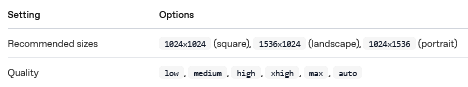

In [ ]:
from openai import OpenAI
from IPython.display import display, Image
import base64

cliente = OpenAI( api_key = OPENAI_API_KEY )

prompt = """
Crie uma ilustração digital de um robô estudando
em uma biblioteca universitária.
O robô deve estar sentado à mesa, usando um notebook,
com livros ao fundo. Estilo moderno, cores suaves,
iluminação natural e composição horizontal.
"""

resultado = cliente.images.generate(
    model="gpt-image-2.5-flare",
    prompt=prompt,
    size="1024x1024",
    quality="high"
)

# Decodifica a imagem retornada em Base64
imagem_bytes = base64.b64decode(
    resultado.data[0].b64_json
)

# Salva a imagem em arquivo
with open("robo_biblioteca.png", "wb") as arquivo:
    arquivo.write(imagem_bytes)

# Exibe a imagem no notebook
display(Image(data=imagem_bytes))

Também é possível gerar mais de uma imagem em um único prompt:

In [ ]:
from openai import OpenAI
from IPython.display import display, Image
import base64

cliente = OpenAI( api_key = OPENAI_API_KEY )

resultado = cliente.images.generate(
    model="gpt-image-2.5-flare",
    prompt="Um robô estudando em uma biblioteca universitária",
    n=2
)

for imagem in resultado.data:
    dados = base64.b64decode(imagem.b64_json)
    display(Image(data=dados))

In [ ]:
from IPython.display import display, Image
import base64

# Exibir a primeira imagem
imagem1 = base64.b64decode(resultado.data[0].b64_json)
display(Image(data=imagem1))

In [ ]:
# Exibir a segunda imagem
imagem2 = base64.b64decode(resultado.data[1].b64_json)
display(Image(data=imagem2))

Você pode usar modelos de linguagem gerais, como o `GPT-6 Luna`, para gerar imagens por meio da API, desde que o modelo seja compatível com a ferramenta de geração de imagens. Nesse caso, o `Luna` interpreta as instruções e aciona a ferramenta específica de imagens.

A diferença é que o modelo de linguagem não gera diretamente os pixels da imagem: ele coordena a operação usando a ferramenta de geração.

**API Responses**

In [ ]:
from openai import OpenAI
from IPython.display import display, Image
import base64

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    input="Crie uma imagem de um robô estudando em uma biblioteca.",
    tools=[{
        "type": "image_generation",
        "model": "gpt-image-2.5-flare"
    }]
)

display(Image(data=base64.b64decode(resposta.output[0].result)))

**Chat Completions**

In [ ]:
from openai import OpenAI
from IPython.display import display, Image
import base64

cliente = OpenAI( api_key=OPENAI_API_KEY )

resposta = cliente.chat.completions.create(
    model="gpt-6-luna",
    messages=[
        {
            "role": "user",
            "content": "Descreva uma imagem de um robô estudando em uma biblioteca."
        }
    ]
)

descricao = resposta.choices[0].message.content

imagem = cliente.images.generate(
    model="gpt-image-2.5-flare",
    prompt=descricao
)

display(Image(data=base64.b64decode(imagem.data[0].b64_json)))

Qual utilizar?

- **Chat Completions**: adequada para aplicações tradicionais de chat, classificação de textos, análise de sentimentos e tarefas em que você controla o histórico e o fluxo de execução.

- **API Responses**: mais conveniente para aplicações que combinam conversação, geração de imagens, busca na web e outras ferramentas, especialmente quando o modelo precisa coordenar várias etapas de uma tarefa.

**Calculadora de Custos**

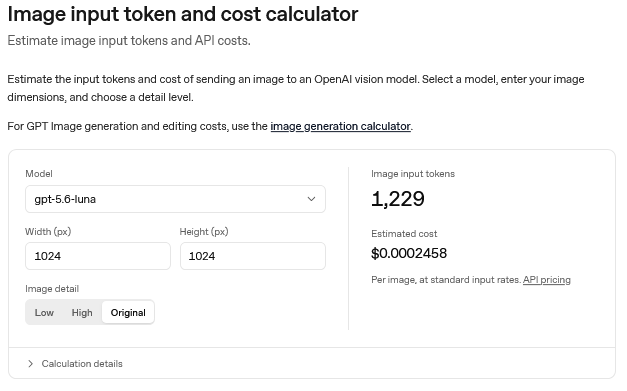

https://developers.openai.com/api/docs/guides/image-cost-calculator

### **Visão**


É possível usar os recursos de visão para compreender imagens.



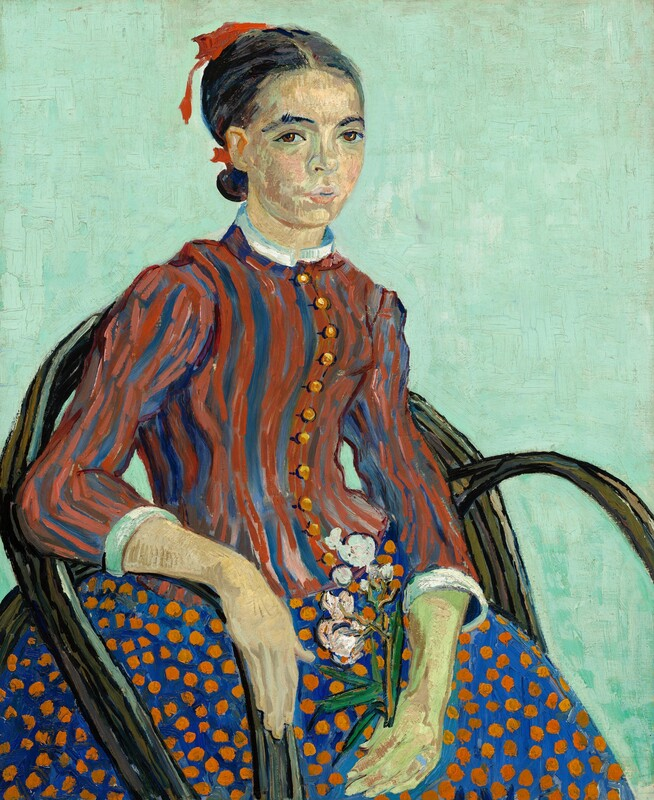

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key=OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    input=[
        {
            "role": "user",
            "content": [
                {
                    "type": "input_text",
                    "text": "Descreva em português o que aparece nesta imagem."
                },
                {
                    "type": "input_image",
                    "image_url": "https://api.nga.gov/iiif/a2e6da57-3cd1-4235-b20e-95dcaefed6c8/full/!800,800/0/default.jpg"
                },
            ],
        }
    ],
)

In [ ]:
print(resposta.output_text)

A imagem mostra uma pintura a óleo de uma jovem sentada em uma cadeira escura de braços curvos. Ela usa um casaco vermelho-escuro com listras azuladas e botões dourados, sobre uma saia azul coberta de círculos alaranjados. Há pequenas flores claras junto ao seu colo. Seu cabelo está preso, enfeitado com uma fita vermelha, e ela olha serenamente para a frente. O fundo verde-claro, com pinceladas visíveis, é simples e destaca a figura.


Considere a seguinte imagem:

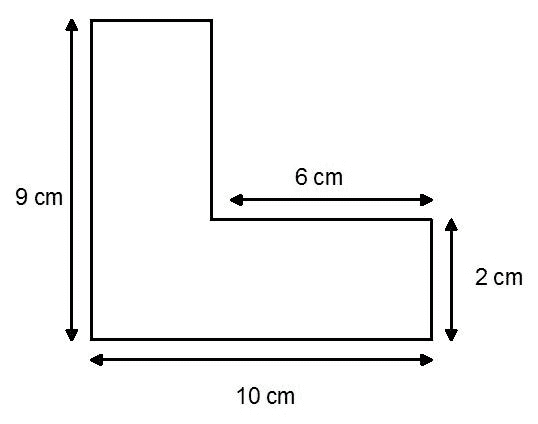

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key=OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    instructions="Você é um assistente útil que me ajuda com exercícios de matemática. Responda em português.",
    input=[
        {
            "role": "user",
            "content": [
                {
                    "type": "input_text",
                    "text": "Qual é a área da figura apresentada na imagem? Explique o cálculo."
                },
                {
                    "type": "input_image",
                    "image_url": "https://media.datacamp.com/legacy/v1716376913/image_8b65a16aa1.png"
                }
            ]
        }
    ]
)

In [ ]:
print(resposta.output_text)

Podemos dividir a figura em dois retângulos:

- Retângulo vertical: largura \(10-6=4\) cm e altura \(9\) cm  
  \(\rightarrow 4\times 9=36\text{ cm}^2\)
- Retângulo inferior à direita: \(6\) cm por \(2\) cm  
  \(\rightarrow 6\times 2=12\text{ cm}^2\)

Somando as áreas: \(36+12=\boxed{48\text{ cm}^2}\).


In [ ]:
from IPython.display import display, Markdown

texto = resposta.output_text

texto = texto.replace(r"\(", "$")
texto = texto.replace(r"\)", "$")
texto = texto.replace(r"\[", "$$")
texto = texto.replace(r"\]", "$$")

display(Markdown(texto))

Podemos dividir a figura em dois retângulos:

- Retângulo vertical: largura $10-6=4$ cm e altura $9$ cm  
  $\rightarrow 4\times 9=36\text{ cm}^2$
- Retângulo inferior à direita: $6$ cm por $2$ cm  
  $\rightarrow 6\times 2=12\text{ cm}^2$

Somando as áreas: $36+12=\boxed{48\text{ cm}^2}$.

`Visão` é a capacidade de um modelo "ver" e compreender imagens. Se houver texto em uma imagem, o modelo também pode entendê-lo. Ele consegue compreender a maioria dos elementos visuais, incluindo objetos, formas, cores e texturas, mesmo que haja algumas limitações.

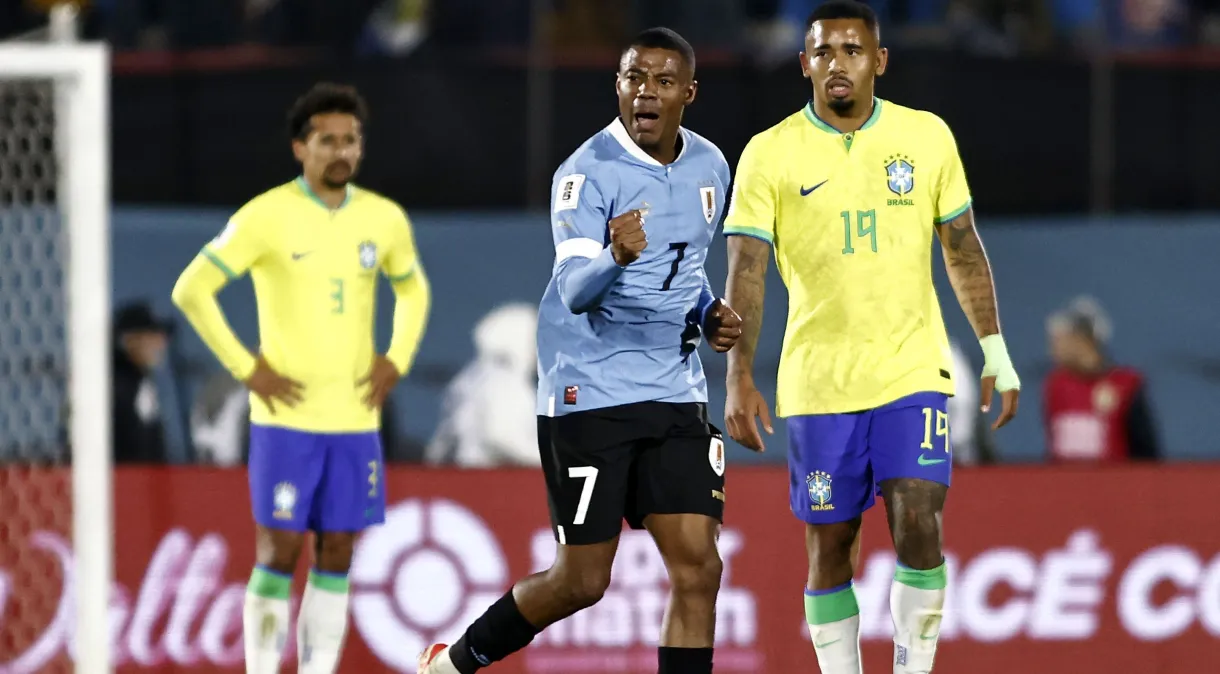

**Tipos de arquivo suportados**

PNG (.png) - JPEG (.jpeg e .jpg) - WEBP (.webp) - GIF não animado (.gif)



In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_text", "text": "o que tem nessa imagem?"},
            {
                "type": "input_image",
                "image_url": "https://www.fatosdesconhecidos.com.br/wp-content/uploads/2023/10/selecao.webp",
            },
        ],
    }],
)

In [ ]:
print(resposta.output_text)

A imagem mostra uma partida de futebol entre Brasil e Uruguai. Um jogador uruguaio com a camisa 7 está ao lado do brasileiro Gabriel Jesus, número 19; outro jogador brasileiro aparece desfocado ao fundo, perto do gol.


### **Modo *JSON***

Uma maneira comum de usar o *endpoint* `chat completions` é instruir o modelo a sempre retornar um objeto `JSON` que faça sentido para o seu caso de uso, especificando isso na mensagem do sistema. Embora isso funcione em alguns casos, ocasionalmente os modelos podem gerar uma saída que não é analisada em objetos JSON válidos.


Para evitar esses erros e melhorar o desempenho do modelo, você pode definir `response_format` como `{ "type": "json_object" }` para ativar o modo `JSON`. Quando o modo `JSON` está ativado, o modelo é restrito a gerar apenas cadeias de caracteres que são analisadas em objetos `JSON` válidos.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.chat.completions.create(
  model = "gpt-6-luna",
  response_format = { "type": "json_object" },
  messages = [
    {"role": "system", "content": "Você é um assistente útil projetado para gerar saída no formato JSON."},
    {"role": "user", "content": "“Quem ganhou a Copa do Mundo de Futebol em 2022?"}
  ]
)

In [ ]:
print(resposta.choices[0].message.content)

{"resposta":"A Argentina ganhou a Copa do Mundo de Futebol de 2022."}


In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.chat.completions.create(
  model = "gpt-4o-mini",
  response_format = { "type": "json_object" },
  messages = [
    {"role": "system", "content": "Você é um assistente útil projetado para gerar saída no formato JSON."},
    {"role": "user", "content": "“Quem ganhou a Copa do Mundo de Futebol em 2022?"}
  ]
)

In [ ]:
print(resposta.choices[0].message.content)

{
  "Copa_do_Mundo_2022": {
    "vencedor": "Argentina",
    "anfitrião": "Catar",
    "data": "20 de novembro a 18 de dezembro de 2022"
  }
}


**Saída Estruturada**

Saídas Estruturadas é um recurso que garante que o modelo sempre gerará respostas que estejam de acordo com o esquema JSON fornecido, para que você não precise se preocupar com a omissão de uma chave necessária pelo modelo ou com a alucinação de um valor de enumeração inválido.

In [ ]:
from openai import OpenAI
from pydantic import BaseModel

cliente = OpenAI( api_key = OPENAI_API_KEY )

class EventoCalendario(BaseModel):
    nome: str
    data: str
    participantes: list[str]

resposta = cliente.responses.parse(
    model="gpt-6-luna",
    input=[
        {"role": "system", "content": "Extraia as informações do evento."},
        {
            "role": "user",
            "content": "Alice e Bob vão a uma feira de ciências na sexta-feira.",
        },
    ],
    text_format = EventoCalendario,
)

evento = resposta.output_parsed

In [ ]:
evento

EventoCalendario(nome='Feira de ciências', data='sexta-feira', participantes=['Alice', 'Bob'])

### **Texto para Fala (*Text to Speech*)**

A API da OpenAI também fornece um *endpoint* para gerar aúdio com base no modelo `TTS` (*`text-to-speech`*). O modelo oferece suporte a vários idiomas.

O *endpoint* de fala recebe três entradas principais: o modelo, o texto que deve ser transformado em áudio e a voz a ser usada para a geração do áudio.

Experimente diferentes vozes (`alloy`, `echo`, `fable`, `onyx`, `nova` e `shimmer`) para encontrar uma que corresponda ao tom e ao público desejados. As vozes atuais são otimizadas para inglês.

O formato de resposta (`response_format`) padrão é `mp3`, mas outros formatos como `opus`, `aac`, `flac` e `pcm` estão disponíveis. A velocidade (`speed`) do áudio gerado pode variar entre 0.25 e 4.

In [ ]:
from openai import OpenAI
from IPython.display import display, Audio

cliente = OpenAI(api_key=OPENAI_API_KEY)

texto = "Eu adoro ciência de dados e processamento de linguagem natural!"
arquivo = "audio.mp3"

with cliente.audio.speech.with_streaming_response.create(
    model="tts-1",
    voice="alloy",
    input=texto,
    speed=0.8,
    response_format="mp3"
) as resposta:
    resposta.stream_to_file(arquivo)

In [ ]:
# reproduz o áudio
display(Audio(arquivo))

In [ ]:
from openai import OpenAI
from IPython.display import display, Audio

cliente = OpenAI(api_key=OPENAI_API_KEY)

texto = """
Central, aqui é a comandante Helena.
Estamos nos aproximando da estação espacial.
Todos os sistemas estão funcionando normalmente.

Espere... Temos um alerta no painel!
A pressão da cabine está caindo.
Equipe, iniciem o protocolo de segurança imediatamente!

Respirem fundo. Temos oxigênio de reserva
e o sistema auxiliar está respondendo.

Conseguimos! A pressão está estabilizada.
Central, situação sob controle.
E, depois dessa, acho que merecemos férias na Terra!
"""

with cliente.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="coral",
    input=texto,
    instructions=(
        "Interprete a fala como uma comandante de missão espacial "
        "em português brasileiro. Comece com voz calma, profissional "
        "e objetiva. Ao perceber o alerta, aumente a urgência e a "
        "tensão, falando mais rapidamente e com firmeza. Ao orientar "
        "a equipe, transmita autoridade e controle. Quando o problema "
        "for resolvido, demonstre alívio e termine com humor leve e "
        "natural. Torne as diferenças emocionais bem perceptíveis."
    ),
    response_format="mp3"
) as resposta:
    resposta.stream_to_file("missao_espacial.mp3")

In [ ]:
display(Audio("missao_espacial.mp3"))

### **Fala para Texto (*Speech to Text*)**

A API da OpenAI fornece dois `endpoints` de fala para texto, transcrições e traduções, com base no modelo `Whisper`. Eles podem ser usados ​​para:

 * Transcrever o áudio para qualquer idioma em que o áudio esteja.
 * Traduzir e transcrever o áudio para o inglês.

Atualmente, os uploads de arquivos estão limitados a 25 MB e os seguintes tipos de arquivo de entrada são suportados: `mp3`, `mp4`, `mpeg`, `mpga`, `m4a`, `wav` e `webm`.

**Transcrição**

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

audio_arquivo = open("/content/audio.mp3", "rb")

transcricao = cliente.audio.transcriptions.create(
  model = "gpt-transcribe",
  file = audio_arquivo
)

In [ ]:
print(transcricao.text)

Eu adoro ciência de dados e processamento de linguagem natural.


**Tradução**

A API de traduções recebe como entrada o arquivo de áudio em qualquer um dos idiomas suportados e transcreve, se necessário, o áudio para o inglês. Isso difere do `endpoint` de transcrição, pois a saída não está no idioma de entrada original e, em vez disso, é traduzida para texto em inglês.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

with open("/content/audio.mp3", "rb") as audio_arquivo:
    traducao = cliente.audio.translations.create(
        model="whisper-1",
        file=audio_arquivo
    )

In [ ]:
print(traducao.text)

I love the science of data and natural language processing.


### **Moderação**

Utilize os modelos de moderação da OpenAI para detectar conteúdo prejudicial em textos e imagens. Você pode classificar entradas isoladas com o *endpoint* de moderação ou solicitar pontuações de moderação junto com uma resposta gerada. Use os resultados para aplicar as políticas da sua aplicação, por exemplo, filtrando conteúdo, encaminhando uma solicitação para análise ou tomando medidas em relação a contas que enviam conteúdo sinalizado.

In [ ]:
from openai import OpenAI

cliente = OpenAI(api_key=OPENAI_API_KEY)

# Texto que será analisado
texto = "Eu quero matar todos eles."

# Executar a moderação
moderacao = cliente.moderations.create(
    model="omni-moderation-latest",
    input=texto
)

# Obter o resultado
resultado = moderacao.results[0]

print("=" * 50)
print("ANÁLISE DE MODERAÇÃO")
print("=" * 50)

print(f"\nTexto analisado: {texto}")

if resultado.flagged:
    print("\nResultado: CONTEÚDO SINALIZADO")
    print("O texto foi identificado como potencialmente problemático.")
else:
    print("\nResultado: CONTEÚDO NÃO SINALIZADO")
    print("O texto não foi sinalizado pelo modelo.")

print("\nCategorias identificadas:")

traducoes = {
    "harassment": "assédio",
    "harassment_threatening": "ameaça de assédio",
    "hate": "ódio",
    "hate_threatening": "ameaça de ódio",
    "illicit": "atividade ilícita",
    "illicit_violent": "atividade ilícita violenta",
    "self_harm": "automutilação",
    "self_harm_instructions": "instruções de automutilação",
    "self_harm_intent": "intenção de automutilação",
    "sexual": "conteúdo sexual",
    "sexual_minors": "conteúdo sexual envolvendo menores",
    "violence": "violência",
    "violence_graphic": "violência explícita"
}

for categoria, sinalizada in resultado.categories.model_dump().items():
    if sinalizada:
        traducao = traducoes.get(categoria, categoria)
        print(f"- {categoria} ({traducao}): Sim")

print("\nObservação: a sinalização é um indicador automatizado,")
print("não uma conclusão definitiva sobre a intenção do autor.")

ANÁLISE DE MODERAÇÃO

Texto analisado: Eu quero matar todos eles.

Resultado: CONTEÚDO SINALIZADO
O texto foi identificado como potencialmente problemático.

Categorias identificadas:
- harassment (assédio): Sim
- harassment_threatening (ameaça de assédio): Sim
- violence (violência): Sim
- harassment/threatening (harassment/threatening): Sim

Observação: a sinalização é um indicador automatizado,
não uma conclusão definitiva sobre a intenção do autor.


### **Busca na Web**

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    tools=[{ "type": "web_search_preview" }],
    input="Quem é o atual presidente do Brasil?",
)

print(resposta)

Response(id='resp_04745172278cb269006ad62cc43e7887d09d0ffd91ab6309d4', created_at=1792421060.0, error=None, incomplete_details=None, instructions=None, metadata={}, model='gpt-6-luna', object='response', output=[ResponseReasoningItem(id='rs_04745172278cb269006ad62cc5883887d0b7b5788161a811dc', summary=[], type='reasoning', content=[], encrypted_content='gAAAAABq1izIsFWJfRqbtTP6DsZRvE6ho82qucCb3DTNcYwfYn7Bfplp95kOZLW3Xg37fYmgGtEVKxqQnh_GgPiBQpy0Vu6zswixCNyZ2LkmBdEY9ELXEFwWB5cgpKeiPUuIlg_knOA5Hg3Cg0zGdv2-HXd-v7E7rAbXVcZ7Lx5I8f8OF7by7TFCjC4MkNdpMLh05zvXxWVmqId5Rdan7mWGMQCmd_s99ZFfYglgDX5gJn_G1abwMKXUE_gmDuowe3zy2oaM_hBnXqFcyfP9NnhKJuuVjMSWDUzst4lcUSZY4IbgDMWRNqvdOny6HG8zfR-oQSZuhCH7dmEoymbT_uwsUw6_NJEpPWSDT-HlXNSKmNxfbm0lNW0oWEdZzSeOG4C2tJ_ASYpIr_JokbXgLUBh-2SUaX5V56WKCMQyClTuOeR7VtZ0ito58aUXtAb7dJr0cXE8WO_kAn2PxGSMy7Alx2dfciKk1a8G_tuHe3BF21dZ-JqkWMMLQsC-6UBG1NcOq7rXcgXb7kW9PxqgUZ8ABJE29Et51jhQcLFVESc8EVo4k9L3JnD74CFK83n326A58ZvUhl4FM-Ls_qDOZjXQnf3Rv_AJn-sqIbDEGqjxRZZyk9thP6vovrQzlXVLbHZuR

In [ ]:
resposta.model_dump_json()

'{"id":"resp_04745172278cb269006ad62cc43e7887d09d0ffd91ab6309d4","created_at":1792421060.0,"error":null,"incomplete_details":null,"instructions":null,"metadata":{},"model":"gpt-6-luna","object":"response","output":[{"id":"rs_04745172278cb269006ad62cc5883887d0b7b5788161a811dc","summary":[],"type":"reasoning","content":[],"encrypted_content":"gAAAAABq1izIsFWJfRqbtTP6DsZRvE6ho82qucCb3DTNcYwfYn7Bfplp95kOZLW3Xg37fYmgGtEVKxqQnh_GgPiBQpy0Vu6zswixCNyZ2LkmBdEY9ELXEFwWB5cgpKeiPUuIlg_knOA5Hg3Cg0zGdv2-HXd-v7E7rAbXVcZ7Lx5I8f8OF7by7TFCjC4MkNdpMLh05zvXxWVmqId5Rdan7mWGMQCmd_s99ZFfYglgDX5gJn_G1abwMKXUE_gmDuowe3zy2oaM_hBnXqFcyfP9NnhKJuuVjMSWDUzst4lcUSZY4IbgDMWRNqvdOny6HG8zfR-oQSZuhCH7dmEoymbT_uwsUw6_NJEpPWSDT-HlXNSKmNxfbm0lNW0oWEdZzSeOG4C2tJ_ASYpIr_JokbXgLUBh-2SUaX5V56WKCMQyClTuOeR7VtZ0ito58aUXtAb7dJr0cXE8WO_kAn2PxGSMy7Alx2dfciKk1a8G_tuHe3BF21dZ-JqkWMMLQsC-6UBG1NcOq7rXcgXb7kW9PxqgUZ8ABJE29Et51jhQcLFVESc8EVo4k9L3JnD74CFK83n326A58ZvUhl4FM-Ls_qDOZjXQnf3Rv_AJn-sqIbDEGqjxRZZyk9thP6vovrQzlXVLbHZuR4XAtxBNIDsQd

In [ ]:
resposta.output_text

'O atual presidente do Brasil é **Luiz Inácio Lula da Silva**. ([gov.br](https://www.gov.br/casacivil/pt-br/.arquivos/mensagem-ao-congresso-nacional-2026.pdf?utm_source=openai))'

A filtragem de domínio em pesquisas na Web permite limitar os resultados a um conjunto específico de domínios. Com o parâmetro `filters`, você pode definir uma lista de permissões de até 20 URLs. Ao formatar URLs, omita o prefixo HTTP ou HTTPS. Por exemplo, use [openai.com](https://) em vez de https://openai.com/.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
  model="gpt-6-luna",
  reasoning={"effort": "low"},
  tools=[
      {
          "type": "web_search",
          "filters": {
              "allowed_domains": [
                  "ufabc.edu.br",
                  "clinicaltrials.gov",
                  "www.who.int",
                  "www.cdc.gov",
                  "www.fda.gov",
              ]
          },
      }
  ],
  tool_choice="auto",
  include=["web_search_call.action.sources"],
  input="Faça uma pesquisa na web sobre como a semaglutida é usada no tratamento do diabetes.",
)

print(resposta.output_text)

## Semaglutida no tratamento do diabetes

**Resumo da pesquisa:** a semaglutida é um medicamento da classe dos agonistas do receptor GLP‑1. É usada para tratar **diabetes tipo 2**: ajuda a controlar a glicose no sangue e, em muitas pessoas, também reduz o peso. Não substitui insulina no diabetes tipo 1.

### Como é usada

- **Injeção semanal:** a dose costuma ser aumentada gradualmente para ajudar a reduzir efeitos gastrointestinais. A dose e o esquema exatos dependem da formulação e da prescrição.
- **Comprimido diário:** há também semaglutida oral; deve ser tomada conforme instruções específicas do produto.
- Pode ser prescrita sozinha ou junto com outros medicamentos para diabetes. Se usada com insulina ou sulfonilureias, o profissional pode precisar ajustar o tratamento para reduzir o risco de hipoglicemia.
- A escolha de usá-la considera o controle glicêmico, outras condições de saúde, possíveis efeitos adversos e preferências da pessoa. Um estudo registrado no ClinicalTrials.gov,

**Localização do usuário**

Para refinar os resultados da pesquisa com base na geografia, você pode especificar a localização aproximada do usuário usando país, cidade, região e/ou fuso horário.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    tools=[{
        "type": "web_search",
        "user_location": {
            "type": "approximate",
            "country": "BR",
            "city": "Santo Andre",
            "region": "Sao Paulo",
        }
    }],
    input="Quais são os melhores restaurantes perto de mim?",
)

print(resposta.output_text)

Estou considerando **Santo André (SP)** como sua região aproximada — não tenho sua localização exata. Algumas boas opções:

- **Rancho dos Peruanos ABC** — comida peruana; aparece entre os mais bem avaliados da cidade no Tripadvisor.
- **Restaurante Jangada** — frutos do mar e pratos japoneses/brasileiros; opção versátil para ir em família.
- **Camarada Camarão** — frutos do mar, com bastante avaliação de clientes.
- **Spazio Santo Disco** — italiana e pizza; boa pedida para jantar.
- **Baby Beef Jardim** — carnes e churrasco, para uma refeição mais caprichada.
- **Grazie Napoli** — italiana e pizza, uma opção mais casual.

Essas opções estão entre as destacadas nas listagens recentes de restaurantes de Santo André; avaliações e horários podem mudar. ([tripadvisor.com.br](https://www.tripadvisor.com.br/Restaurants-g303624-Santo_Andre_State_of_Sao_Paulo.html?utm_source=openai))

Se você me disser **seu bairro**, além do tipo de comida e faixa de preço, posso sugerir lugares realmente ma

**Imagens**

A busca na web pode retornar resultados de imagens juntamente com resultados de texto convencionais. Utilize a pesquisa de imagens quando sua aplicação precisar de recursos visuais atuais ou fundamentados em informações da web, como fotos de produtos, pontos turísticos, lugares, eventos ou referências visuais.

Para utilizar a pesquisa de imagens, configure `search_content_types` para incluir `image`. Adicione `text` também quando desejar obter textos de apoio que ajudem o modelo a resumir, classificar ou explicar as imagens recuperadas.

Utilize `image_settings` para controlar as características específicas das imagens:

- `max_results`: define o número máximo de resultados de imagens. Deve ser um número inteiro positivo.
- `caption`: solicita descrições curtas das imagens, quando disponíveis.

In [5]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

resposta = cliente.responses.create(
    model="gpt-6-luna",
    reasoning={"effort": "low"},
    tools=[
        {
            "type": "web_search",
            "search_content_types": ["image", "text"],
            "image_settings": {
                "max_results": 3,
                "caption": True,
            },
        }
    ],
    include=["web_search_call.results"],
    input=(
        "Pesquise imagens recentes da Ponte Golden Gate ao pôr do sol "
        "e fontes textuais com informações sobre esse local."
    ),
)

print(resposta.output)

[ResponseReasoningItem(id='rs_094efba862da1f56006ad67311381887d1abe3ab102c1f9227', summary=[], type='reasoning', content=[], encrypted_content='gAAAAABq1nMeVqSA0tSzo63JSvz8gRLM3JjdRxMsjllyJch_SKL5wyAaykN0z2Tj7888ULPOrFRDzRxEAH1tMz1-DnfTB_zWq6oYcvkapzMR9a-_KqPI6nK8Vo2qKZG0-qvRJuYs5a19Z1cpT0ve7Fk8SToJVDrzTshmoKO2tdnPCBx00jeY2cjDFLx9OGJwStq42iYvPYhECN6zd9dIQpvKdgl6YCDITZjEeEUvZF-SBxt-2RtTtJhFTu9Y91WoGg8Z1sknm04YrqU13iEeloYIheuHpB_S5AocpWF1Jt34aGgBN8TRN0clCuddZ8AKlgH-IxBAImI1gbDZjeerzqwPJwehWB56Quq3na4dlYjrQGmOl2bY9i2II0ZVdpz0mubSaZHnkTnOCKYbGBSo5lW7OQWcHFppl9FtWfT953IxItzUCzpnhLT7ezq-6ZlCJ0Fg19N9YCtelaRED0hzUvGqiWFBTMF78MTJ25p11WWnPBwjVLBpPc4w7gy96TrnNjiPhVmf1usokyj-cNN2HcaDxSeSUJUqaYU0tVx5a3n5wvqAYtwYegLqMH8IvuoHh8zLwcWOTHfIPDUEbDWmq9lhUJHA1nA9ICRnnGu07nTbPRe4AwsULrXxzmIKa1nbGgXeX6mM98_dCCHQWchJc79Rq6kXnQWaLlqCFwq4VBhFDYejiMGesdy_vxX9HG7u5C5PwRlhtkqtkRdoRKagTnQzt9_76omBNb-gC69meLLajln-oU-f9Nyf5FLvAmMN2fv6F9s5gvUjX-1RbjO5v_FsfomnnMrUpy9v7c7fjlEjZYH77oQL00GuATwuLo0Y9BL3V9KYAVR9FSN7BJk78h_M

In [ ]:
for item in resposta.output:
    if item.type == "web_search_call":
        print(item.model_dump_json(indent=2))

In [8]:
from IPython.display import display, HTML
from html import escape
import requests
from urllib.parse import urlparse
from IPython.display import Image as ColabImage
from IPython.display import display as mostrar

# Extrair os resultados da pesquisa
imagens = []

for item in resposta.output:
    if item.type == "web_search_call":
        resultados = item.model_dump().get("results", [])

        for resultado in resultados:
            if resultado.get("type") == "image_result":
                imagens.append({
                    "url": resultado.get("image_url"),
                    "miniatura": resultado.get("thumbnail_url"),
                    "legenda": resultado.get("caption") or "Imagem encontrada",
                    "fonte": resultado.get("source_website_url")
                })

# Criar uma galeria HTML
cartoes = []

for i, imagem in enumerate(imagens, start=1):
    url = imagem["miniatura"] or imagem["url"]

    if not url:
        continue

    legenda = escape(imagem["legenda"])
    fonte = imagem["fonte"]
    link = escape(fonte or imagem["url"] or url, quote=True)
    url_img = escape(url, quote=True)

    cartoes.append(f"""
    <div style="
        background: white;
        border-radius: 16px;
        overflow: hidden;
        box-shadow: 0 4px 14px rgba(0,0,0,0.12);
        border: 1px solid #e5e7eb;
        margin: 8px;
        min-width: 0;
    ">
        <a href="{link}" target="_blank"
           style="text-decoration:none;color:inherit;">
            <img src="{url_img}"
                 alt="{legenda}"
                 style="width:100%;height:210px;object-fit:cover;
                        display:block;background:#f3f4f6;"
                 onerror="this.style.display='none'">
        </a>
        <div style="padding:15px;">
            <div style="font-size:12px;color:#64748b;
                        margin-bottom:8px;">
                IMAGEM {i:02d}
            </div>
            <div style="font-size:15px;font-weight:600;
                        line-height:1.5;color:#1e293b;">
                {legenda}
            </div>
            <a href="{link}" target="_blank"
               style="display:inline-block;margin-top:12px;
                      color:#2563eb;font-size:13px;
                      text-decoration:none;">
                Abrir fonte ↗
            </a>
        </div>
    </div>
    """)

if cartoes:
    galeria = f"""
    <div style="font-family:Arial,sans-serif;">
        <div style="padding:18px 8px;">
            <div style="font-size:26px;font-weight:700;color:#0f172a;">
                Galeria de imagens
            </div>
            <div style="color:#64748b;margin-top:6px;">
                {len(cartoes)} imagens encontradas na pesquisa
            </div>
        </div>
        <div style="
            display:grid;
            grid-template-columns:repeat(auto-fit,minmax(230px,1fr));
            gap:14px;
        ">
            {''.join(cartoes)}
        </div>
    </div>
    """
    display(HTML(galeria))
else:
    print("Nenhuma imagem foi encontrada nos resultados retornados.")

### **Interpretador de Código**

A ferramenta `Code Interpreter` permite que modelos escrevam e executem código `Python` em um ambiente *sandbox* para resolver problemas complexos em domínios como análise de dados, codificação e matemática. Use-a para:

Aqui está um exemplo de chamada da `API Responses` com uma chamada de ferramenta para o `Code Interpreter`:

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

instructions = """
Você é um tutor particular de matemática. Quando lhe for feita uma pergunta de matemática,
escreva e execute o código usando a ferramenta Python para responder à pergunta.
"""

resposta = cliente.responses.create(
    model = "gpt-6-luna",
    tools = [
        {
            "type": "code_interpreter",
            "container": {"type": "auto"}
        }
    ],
    instructions = instructions,
    input = "Preciso resolver a equação 3x + 11 = 14. Você pode me ajudar?",
)

print(resposta.output)

[ResponseReasoningItem(id='rs_07d47a69d1e7b555006ad62dade6d887d096187ffbc87e6708', summary=[], type='reasoning', content=[], encrypted_content='gAAAAABq1i2wQe5KPWY8_jMIZOloRIasztsyNlMjzeoexQw0-Ru-_7nfitYu_7xCeht8ZKftprEIlXOty1RlfxjZOkBw3h78PKeK-MtUYooE4tH0b6jbPlcpDX5o6bDe4ZZlhX3hkhfun0U3tJIlJe686_s32XHi5dBvqo8aTDr_gaiEZB4VezfLg6Z2-zUCj2XXiTnUb2dewS-CE7G2LQ_xxwhukLEcvTQiNQgZE1LbHRUYXvUyXkZ4C7oVTmKuec-4VfPvjs9J-8_6PeMUhC6qFjUzZAe3Jqm4IZhaqasm2gNrJ_ct9sWauRmIWo6nlEm4KN_fluHGgIkA0rDcxnXoZLx97ujsGf45QNrcR3UyyeDKCeu25LOQzbHlLICQhlm_SY9FsPNEfwPnnvividawXABVchdpipA3YkEYFSYSMiG83MmwbFrxasK3MPUaFKXeOE5IaNZMt1KFpoc5JkJxx3uycAyU_gM6ASh0YMouWYU9KShbmhOanEKiL_so9ogjiCbhzlxDrN0cP7hRy5NMiSgp_Mz690r9_TCA_C7hbk6FmNLmc_fs_c8hclYPFBUjKaIO-_tAmMrTqtzg8X9GOzBjCwBcBbCYvrBeJByXPujE29ya87XmrJsggJ2TwWEG9_uHI5gzKq0RtAf3fCEm_TKo4O4XpHSxGyHHOrjYA5dNSwZDcD4jimN2_JbvCweFSt0UBSKBCaLFkLxLCj_k8jzL344X4tgXtk4zwFyj9qtrbllORI-KGwXTUlwuxbaYxiu13zU7Rl7m4DBqSxhKa9GguL3T3fuymIDerHqzE5g-sSLjix9L6v_CLMlLyU7eewceluB0nvu1KQARAu7M

In [ ]:
resposta.output_text

'Claro! Vamos resolver:\n\n\\[\n3x + 11 = 14\n\\]\n\nSubtraindo 11 dos dois lados, temos \\(3x = 3\\). Dividindo por 3:\n\n\\[\n\\boxed{x = 1}\n\\]'

In [ ]:
from IPython.display import display, Markdown

# Exibir a resposta com formatação Markdown e LaTeX
display(Markdown(resposta.output_text))

Claro! Vamos resolver:

\[
3x + 11 = 14
\]

Subtraindo 11 dos dois lados, temos \(3x = 3\). Dividindo por 3:

\[
\boxed{x = 1}
\]

A ferramenta `Code Interpreter` requer um objeto `container`. Um `container` é uma máquina virtual totalmente isolada na qual o modelo pode executar código Python. Esse `container` pode conter arquivos que você carrega ou que ele gera.

In [ ]:
from openai import OpenAI

cliente = OpenAI( api_key = OPENAI_API_KEY )

container = cliente.containers.create(name="teste-container")

resposta = cliente.responses.create(
    model = "gpt-6-luna",
    tools = [{
        "type": "code_interpreter",
        "container": container.id
    }],
    tool_choice="required",
    input = "use a ferramenta python para calcular quanto é 4 * 3,82 e então encontre sua raiz quadrada"
)

print(resposta.output_text)

\(4 \times 3{,}82 = 15{,}28\). A raiz quadrada de \(15{,}28\) é aproximadamente **3,909**.


In [ ]:
from IPython.display import display, Markdown

# Exibir a resposta com formatação Markdown e LaTeX
display(Markdown(resposta.output_text))

\(4 \times 3{,}82 = 15{,}28\). A raiz quadrada de \(15{,}28\) é aproximadamente **3,909**.